# Why do deliveries arrive late, and can we see it coming?

**Context.** 96,470 delivered orders from the Olist marketplace (Brazil, 2016-2018).
Each order has a promised delivery date shown to the customer at checkout.

**Questions**
1. How often is the promise broken, where, and when?
2. What does a late delivery cost in customer satisfaction?
3. Where is the time lost: at the seller or during transport?
4. Can we flag risky orders **at checkout**, early enough to act?

Data comes from the `fct_orders` mart of [ecommerce-data-pipeline](https://github.com/mohfofana/ecommerce-data-pipeline).

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick
from delay.data import load_orders

NAVY, ORANGE, GREY = "#0f3d5c", "#e4572e", "#9aa5b1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
FIG = "../reports/figures/"

df = load_orders()
print(f"{len(df):,} delivered orders | late rate {df.is_late.mean():.1%} | "
      f"{df.purchased_at.min():%b %Y} to {df.purchased_at.max():%b %Y}")

96,470 delivered orders | late rate 6.8% | Sep 2016 to Aug 2018


## 1. How often, where, when

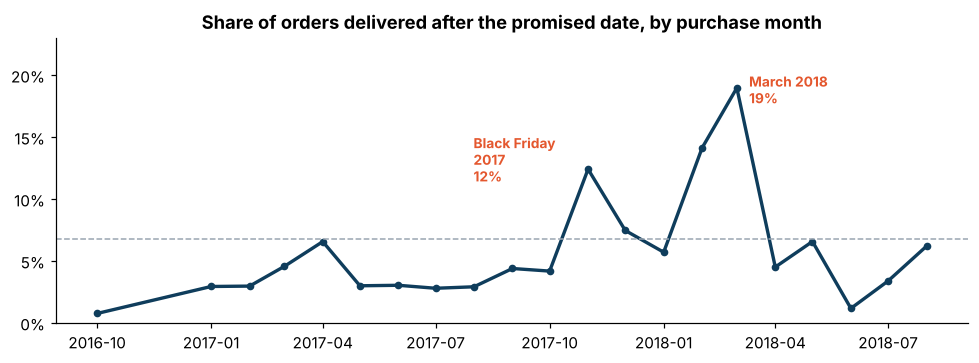

In [2]:
monthly = (df.set_index("purchased_at").resample("MS")
             .agg(orders=("order_id", "size"), late_rate=("is_late", "mean")))
monthly = monthly[monthly.orders >= 200]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(monthly.index, monthly.late_rate, color=NAVY, lw=2.2, marker="o", ms=4)
ax.axhline(df.is_late.mean(), color=GREY, ls="--", lw=1)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_ylim(0, 0.23)
for d, label, off in [("2017-11-01", "Black Friday\n2017", (-75, -8)), ("2018-03-01", "March 2018", (8, -10))]:
    v = monthly.loc[d, "late_rate"]
    ax.annotate(f"{label}\n{v:.0%}", (pd.Timestamp(d), v), xytext=off,
                textcoords="offset points", fontsize=9, color=ORANGE, fontweight="bold")
ax.set_title("Share of orders delivered after the promised date, by purchase month")
plt.tight_layout(); plt.savefig(FIG + "late_rate_by_month.png", bbox_inches="tight"); plt.show()

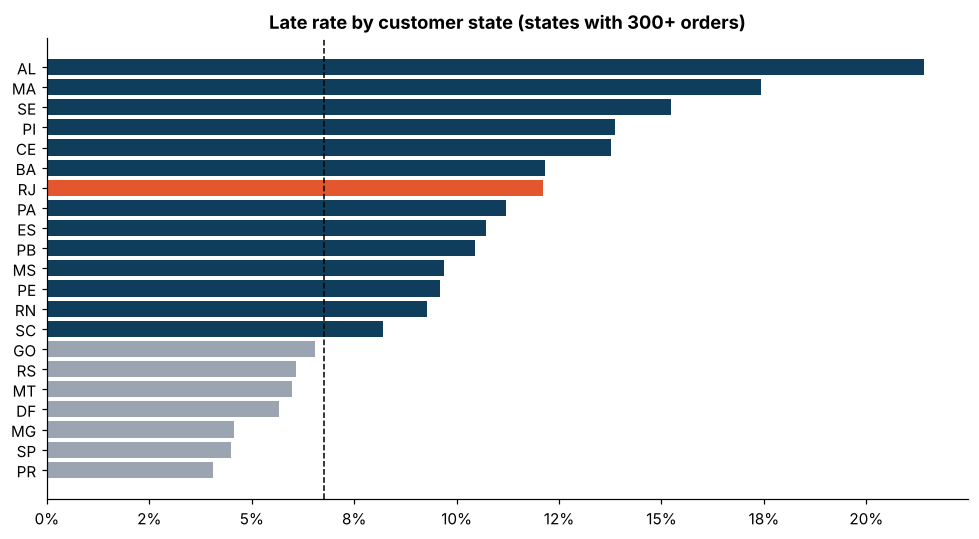

,orders,late_rate,median_days
customer_state,,,
AL,397,21.4%,22.3
MA,717,17.4%,19.2
SE,335,15.2%,18.0
PI,476,13.9%,16.3
CE,1279,13.8%,18.2
BA,3256,12.2%,16.9


In [3]:
by_state = (df.groupby("customer_state")
              .agg(orders=("order_id", "size"), late_rate=("is_late", "mean"),
                   median_days=("actual_days", "median"))
              .query("orders >= 300").sort_values("late_rate"))
fig, ax = plt.subplots(figsize=(9, 5))
colors = [ORANGE if s in ("RJ",) else (NAVY if r > df.is_late.mean() else GREY)
          for s, r in zip(by_state.index, by_state.late_rate)]
ax.barh(by_state.index, by_state.late_rate, color=colors)
ax.axvline(df.is_late.mean(), color="black", ls="--", lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_title("Late rate by customer state (states with 300+ orders)")
plt.tight_layout(); plt.savefig(FIG + "late_rate_by_state.png", bbox_inches="tight"); plt.show()
by_state.sort_values("late_rate", ascending=False).head(6).style.format({"late_rate": "{:.1%}", "median_days": "{:.1f}"})

**Reading.** Lateness is concentrated in time (Black Friday 2017, then February-March 2018)
and in space: the North-East (AL, MA, SE, PI, CE, BA) is far above average. **Rio de Janeiro**
(orange) stands out: a large, close-to-São-Paulo market with almost twice the national late rate,
which points to last-mile difficulties rather than distance.

## 2. What a late delivery costs

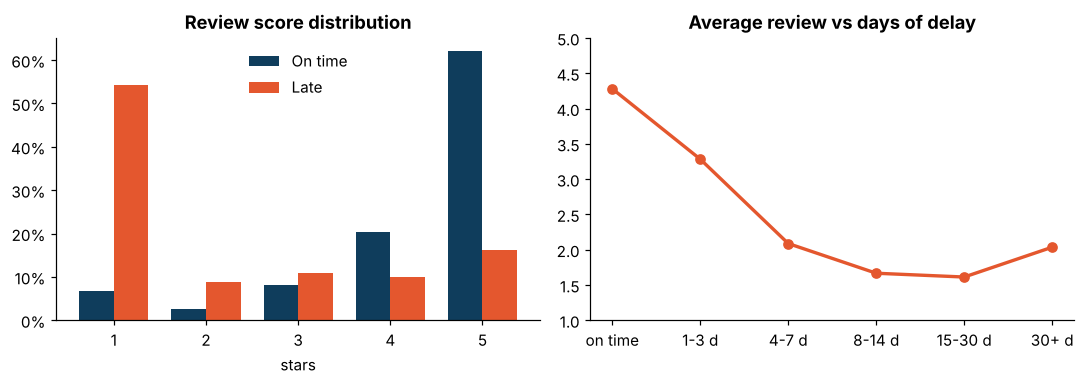

Average review: on time 4.28, late 2.26
1-2 star reviews: on time 10%, late 63%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
share = (df.groupby("is_late").review_score.value_counts(normalize=True)
           .unstack(0).rename(columns={0: "On time", 1: "Late"}))
share.plot.bar(ax=axes[0], color=[NAVY, ORANGE], width=0.75, rot=0)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
axes[0].set_title("Review score distribution"); axes[0].set_xlabel("stars")
axes[0].legend(frameon=False)

late = df[df.is_late == 1].copy()
late["delay_bucket"] = pd.cut(late.delay_days, [0, 3, 7, 14, 30, 400],
                              labels=["1-3 d", "4-7 d", "8-14 d", "15-30 d", "30+ d"])
curve = late.groupby("delay_bucket", observed=True).review_score.mean()
axes[1].plot(["on time"] + list(curve.index.astype(str)),
             [df[df.is_late == 0].review_score.mean()] + list(curve.values),
             color=ORANGE, marker="o", lw=2.2)
axes[1].set_ylim(1, 5); axes[1].set_title("Average review vs days of delay")
plt.tight_layout(); plt.savefig(FIG + "reviews_vs_delay.png", bbox_inches="tight"); plt.show()

print(f"Average review: on time {df[df.is_late==0].review_score.mean():.2f}, late {late.review_score.mean():.2f}")
print(f"1-2 star reviews: on time {(df[df.is_late==0].review_score<=2).mean():.0%}, late {(late.review_score<=2).mean():.0%}")

**Reading.** A late order loses on average **2 stars**. Customers tolerate up to 3 days of delay
(3.3/5), then satisfaction collapses below 2.1/5 from the 4th day. The problem is not lateness
alone but lateness of **more than 3 days**.

## 3. Where the time is lost

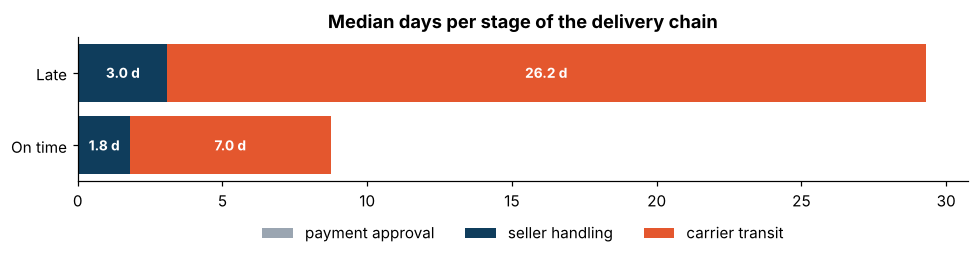

Late rate when the seller hands over after its deadline: 20.8% vs 5.4% otherwise
Share of late orders with a missed seller hand-over: 28%


In [5]:
stages = ["approval_days", "seller_handling_days", "carrier_transit_days"]
med = df.groupby("is_late")[stages].median().rename(index={0: "On time", 1: "Late"})
fig, ax = plt.subplots(figsize=(9, 2.6))
left = np.zeros(2)
for col, color, label in zip(stages, [GREY, NAVY, ORANGE], ["payment approval", "seller handling", "carrier transit"]):
    ax.barh(med.index, med[col], left=left, color=color, label=label)
    for i, v in enumerate(med[col]):
        if v > 1: ax.text(left[i] + v / 2, i, f"{v:.1f} d", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += med[col].values
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_title("Median days per stage of the delivery chain")
plt.tight_layout(); plt.savefig(FIG + "delivery_stages.png", bbox_inches="tight"); plt.show()

missed = df.groupby("seller_missed_handover").is_late.mean()
print(f"Late rate when the seller hands over after its deadline: {missed[True]:.1%} vs {missed[False]:.1%} otherwise")
print(f"Share of late orders with a missed seller hand-over: {df[df.is_late==1].seller_missed_handover.mean():.0%}")

In [6]:
df["distance_band"] = pd.cut(df.seller_customer_distance_km, [-1, 0, 500, 1000, 2000, 5000],
                             labels=["same state", "< 500 km", "500-1,000 km", "1,000-2,000 km", "> 2,000 km"])
dist = df.groupby("distance_band", observed=True).agg(orders=("order_id", "size"),
        late_rate=("is_late", "mean"), median_days=("actual_days", "median"), promised=("promised_days", "median"))
dist.style.format({"late_rate": "{:.1%}", "median_days": "{:.1f}", "promised": "{:.0f}", "orders": "{:,}"})

,orders,late_rate,median_days,promised
distance_band,,,,
same state,"34,690",4.5%,6.5,18
< 500 km,"32,422",7.5%,11.1,25
"500-1,000 km","15,607",6.9%,12.8,27
"1,000-2,000 km","7,477",9.8%,15.8,30
"> 2,000 km","6,274",11.7%,18.2,34


**Reading.** Sellers are slower on late orders (3.0 vs 1.75 days) and a missed hand-over
multiplies the late rate by ~4, but it explains only **28 %** of late orders. The bulk of the
gap is **transport**: 26 days in transit for late orders vs 7 on time. Distance matters
(4.5 % late within a state, 11.7 % beyond 2,000 km) while the promised lead time barely adapts to it.

## 4. Flagging risky orders at checkout

Constraint: use only what is known when the customer pays (no handling or transit times).
Main features: promised lead time, distance, states, basket, freight, and **history computed
only on orders already delivered at that moment**: the seller's past late rate, the route's
recent real lead time and the *slack* between promise and that reality.

Split **by time** (train before March 2018, test after): a random split would leak future
information about the same weeks and sellers.

In [7]:
from delay.features import build_features
from delay.model import time_split, baseline, gradient_boosting, evaluate

feat = build_features(df)
s = time_split(feat)
models = {"Logistic regression": baseline(), "Gradient boosting": gradient_boosting()}
rows, probas = {}, {}
for name, m in models.items():
    m.fit(s.X_train, s.y_train)
    probas[name] = m.predict_proba(s.X_test)[:, 1]
    rows[name] = evaluate(s.y_test, probas[name])
res = pd.DataFrame(rows).T
print(f"train {len(s.X_train):,} orders | test {len(s.X_test):,} orders | test late rate {s.y_test.mean():.1%}")
res.style.format("{:.3f}")

train 57,317 orders | test 39,153 orders | test late rate 7.0%


,roc_auc,pr_auc,base_rate,precision_top10,recall_top10,lift_top10
Logistic regression,0.656,0.110,0.070,0.128,0.183,1.826
Gradient boosting,0.725,0.171,0.070,0.186,0.266,2.656


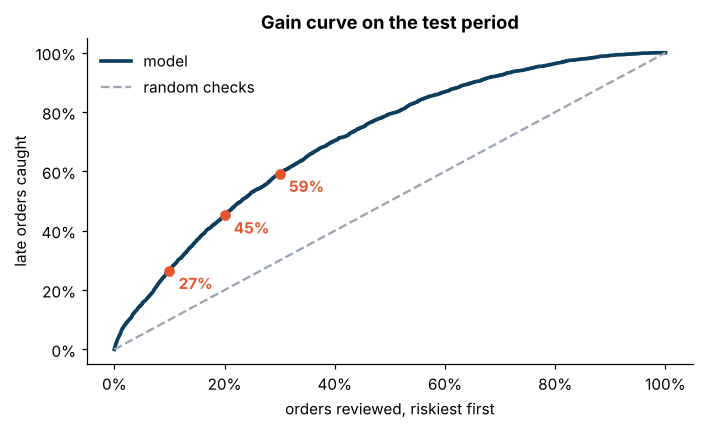

In [8]:
p = probas["Gradient boosting"]
order = np.argsort(-p); y = s.y_test.values[order]
share_checked = np.arange(1, len(y) + 1) / len(y)
captured = np.cumsum(y) / y.sum()
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(share_checked, captured, color=NAVY, lw=2.4, label="model")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", label="random checks")
for k in (0.1, 0.2, 0.3):
    v = captured[int(k * len(y)) - 1]
    ax.scatter([k], [v], color=ORANGE, zorder=3)
    ax.annotate(f"{v:.0%}", (k, v), xytext=(6, -12), textcoords="offset points", color=ORANGE, fontweight="bold")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_xlabel("orders reviewed, riskiest first"); ax.set_ylabel("late orders caught")
ax.set_title("Gain curve on the test period"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG + "gain_curve.png", bbox_inches="tight"); plt.show()

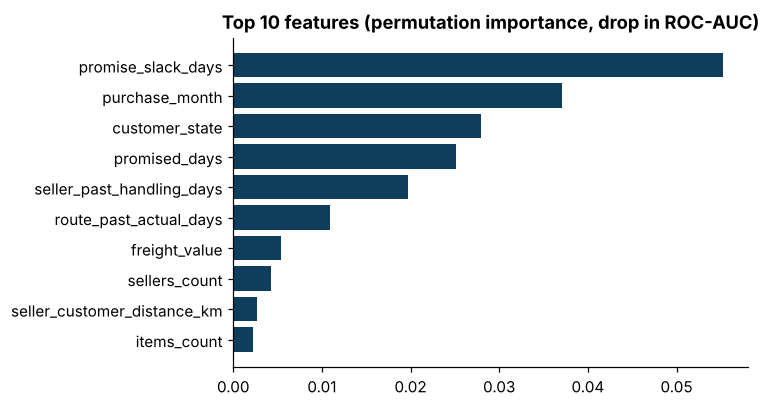

In [9]:
from sklearn.inspection import permutation_importance
gb = models["Gradient boosting"]
sample = s.X_test.sample(8000, random_state=0)
imp = permutation_importance(gb, sample, s.y_test.loc[sample.index], scoring="roc_auc",
                             n_repeats=5, random_state=0)
imp = pd.Series(imp.importances_mean, index=sample.columns).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp.values, color=NAVY)
ax.set_title("Top 10 features (permutation importance, drop in ROC-AUC)")
plt.tight_layout(); plt.savefig(FIG + "feature_importance.png", bbox_inches="tight"); plt.show()

**Reading.** The gradient boosting model reaches a ROC-AUC around **0.72** on months it never saw.
That is modest, and expected: most of the delay happens in transport, after checkout, driven by
events no order-level feature captures. It is still **useful**: reviewing the 10 % riskiest orders
catches about **2.7x** more late orders than random checks, and the 30 % riskiest catch more than
half of them. The most important signals are the slack between the promise and the route's
recent reality, and the seller's track record.

## 5. Recommendations

1. **Make the promise route-aware.** The promised date barely changes with distance. Using the
   route's recent real lead time (as computed here) to set the promise for the North-East and
   long routes would turn many "late" orders into "on time" ones at no logistic cost.
2. **Act before day 4.** Satisfaction collapses after 3 days of delay. Orders flagged at risk
   should get proactive communication and priority handling before that threshold.
3. **Seller hand-over SLA.** A missed hand-over multiplies the late rate by 4. Alerting sellers
   approaching their shipping deadline is cheap and targets a quarter of late orders.
4. **Investigate Rio de Janeiro.** Late rate close to the North-East despite the short distance:
   a last-mile problem worth a dedicated carrier review.

*Limits: distances use state capitals; the test period (spring-summer 2018) is calmer than the
training peaks, so metrics may vary by season.*